# Revisiting Joint and Conditional Probability Mass Functions

##  Introduction

- Our journey from probability space to inference is concluded
- The next topic is Markov Chains, a tool for modeling temporal dependence and evolution of a process over time
- To gradually introduce them, we're reviewing 
    - Joint, marginal and conditional probability mass functions
    - Conditional expectation
- This is to provide a meaningful structure for a analyis of a random/stochastic process that is not IID

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Example: The Weather

- Let $X_t$ be the recorded precipitation `PRCP` for date $t$ for Charlottesville weather station `US1VACRC002`
- If $X_t$ is zero, the day is **dry**, and **wet** if $PRCP_t>0$. 

In [2]:
df = pd.read_csv('./data/cville_weather.csv') # Load data
df = df.loc[df['STATION'] == 'US1VACRC002', :] # Filter to Cville
df['DATE'] = pd.to_datetime(df['DATE']) # Convert to datetime
print(f"Are dates ordered? {df['DATE'].is_monotonic_increasing}")
#df = df.sort_values('DATE').reset_index(drop=True) # Sort by date

# Preserve missing precipitation instead of calling it Dry.
df['PRCP_gtr0'] = (df['PRCP'] > 0).where(df['PRCP'].notna())
print(f"Missing precipitation amounts: {df['PRCP'].isna().sum()}")
df.head()

Are dates ordered? True
Missing precipitation amounts: 7


,STATION,NAME,DATE,DAPR,DAPR_ATTRIBUTES,MDPR,MDPR_ATTRIBUTES,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,SNWD,SNWD_ATTRIBUTES,PRCP_gtr0
0,US1VACRC002,"CHARLOTTESVILLE 0.5 NNE, VA US",2024-01-04,NaN,NaN,NaN,NaN,0.03,",,N",NaN,NaN,NaN,NaN,True
1,US1VACRC002,"CHARLOTTESVILLE 0.5 NNE, VA US",2024-01-07,NaN,NaN,NaN,NaN,1.08,",,N",NaN,NaN,NaN,NaN,True
2,US1VACRC002,"CHARLOTTESVILLE 0.5 NNE, VA US",2024-01-09,NaN,NaN,NaN,NaN,0.24,",,N",NaN,NaN,NaN,NaN,True
3,US1VACRC002,"CHARLOTTESVILLE 0.5 NNE, VA US",2024-01-10,NaN,NaN,NaN,NaN,3.00,",,N",NaN,NaN,NaN,NaN,True
4,US1VACRC002,"CHARLOTTESVILLE 0.5 NNE, VA US",2024-01-24,NaN,NaN,NaN,NaN,0.00,",,N",0.0,",,N",NaN,NaN,False


<Axes: xlabel='PRCP', ylabel='Density'>

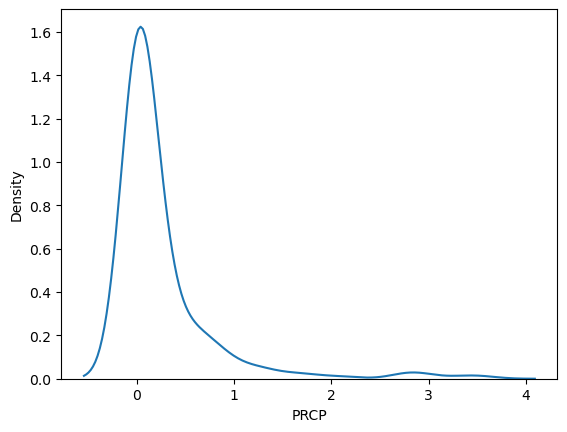

In [3]:
sns.kdeplot(df['PRCP'])

<Axes: xlabel='DATE', ylabel='PRCP'>

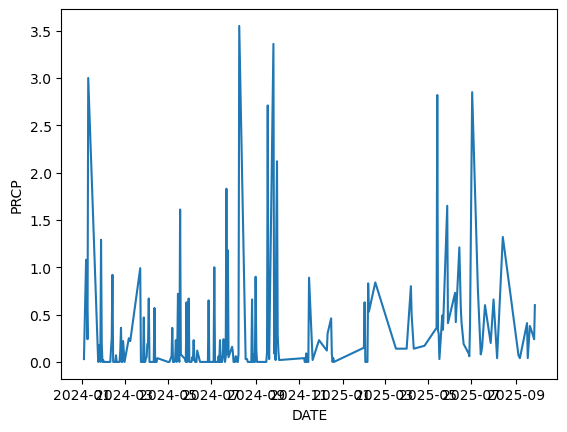

In [4]:
sns.lineplot(x=df['DATE'], y=df['PRCP'])

### Raw Counts

- We can pair the current weather, `Y_t`, with tomorrow's weather $Y_{t+1}$ or `Y_tp1`
- Pair each category $Y_t$ with the following category $Y_{t+1}$. `shift(-1)` places the following row's value beside the current row's value; it does not change the observations' order.

- By cross tabulating $Y_t$ and $Y_tp1$, we can observe how current weather seems to predict future weather

In [5]:
df['y_t'] = df['PRCP_gtr0'].map({False:'Dry', True:'Wet'})
df['y_tp1'] = df['PRCP_gtr0'].shift(-1).map({False:'Dry', True:'Wet'}) # Shift into the future
pd.crosstab(df['y_t'], df['y_tp1'])

y_tp1,Dry,Wet
y_t,,
Dry,86,35
Wet,37,98


### The Joint PMF

- Divide each cell's count by the **total number of complete pairs**, $N$, to estimate the joint PMF:
$$\widehat P(Y_{t+1}=j, Y_t=i )=\frac{\sum_{t=1}^T \mathbb{I} \{ Y_{t+1}=j, Y_t=i \}}{T}.$$
- For Pandas, `normalize=True` performs this calculation. 
- The **whole table** sums to 1; an individual row generally does not, and the heatmap displays these same joint probabilities

In [6]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
tab

y_tp1,Dry,Wet
y_t,,
Dry,0.335938,0.136719
Wet,0.144531,0.382812


<Axes: xlabel='y_tp1', ylabel='y_t'>

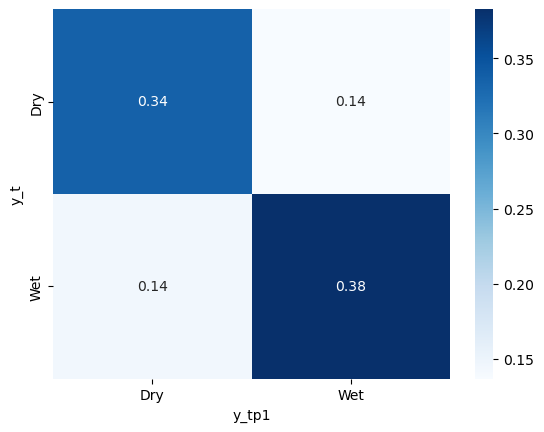

In [7]:
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

### The Marginal PMF

- To describe just one of the two variables, sum over the other:

$$\widehat P(Y_{t+1}=j )=\frac{ \sum_{i} \sum_{t=1}^T \mathbb{I} \{ Y_{t+1}=j, Y_t=i \}}{T}.$$

- This is called the **marginal PMF**, since we've essentially integrated $Y_t$ out of the situation, leaving us only with $Y_{t+1}$
- With `margins=True`, the **All column** contains the row sums: the marginal distribution of the current category. The **All row** contains the column sums: the marginal distribution of the following category. The bottom-right entry is 1 for both

In [8]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
tab

y_tp1,Dry,Wet,All
y_t,,,
Dry,0.335938,0.136719,0.472656
Wet,0.144531,0.382812,0.527344
All,0.480469,0.519531,1.000000


<Axes: xlabel='y_tp1', ylabel='y_t'>

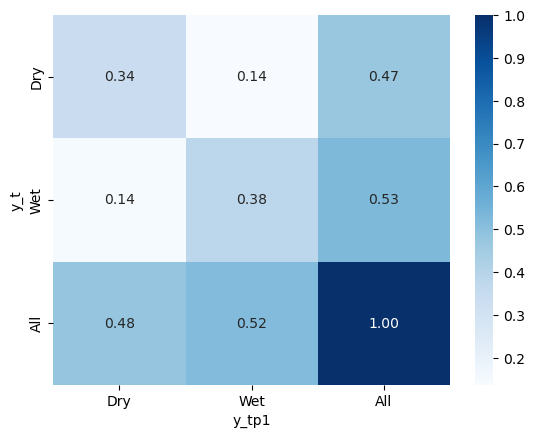

In [9]:
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

## The Conditional
- One of the most important relationships in probability is conditional probability: What is the probability that $Y_{t+1}=j$ given that $Y_t = i$? 
$$
\text{pr}[ Y_{t+1}= j | Y_{t} = i] = \dfrac{\text{pr}[ Y_{t+1}= j , Y_{t} = i]}{\text{pr}[ Y_{t+1}= j ]} = \dfrac{\text{Joint}}{\text{Marginal}}
$$
- Empirically, this equals
$$
\widehat{\text{pr}}[ Y_{t+1}= j | Y_{t} = i] = \dfrac{\frac{1}{T} \sum_{t=1}^T \mathbb{I} \{ Y_{t+1}=j, Y_t=i \}}{\frac{1}{T} \sum_{t=1}^T \mathbb{I} \{  Y_t=j \}}
$$
- Adjust `normalize = 'index'` to get this

In [10]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab

y_tp1,Dry,Wet
y_t,,
Dry,0.710744,0.289256
Wet,0.274074,0.725926


<Axes: xlabel='y_tp1', ylabel='y_t'>

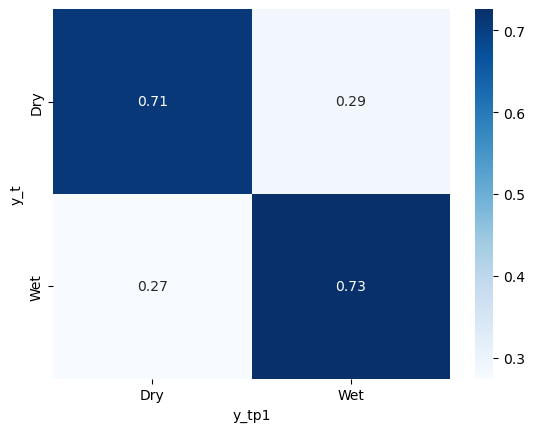

In [11]:
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

### Binning a Continuous Variable

- Dry/Wet discards the amount of precipitation on wet observations. To keep some information about size, divide the recorded amounts into five categories:

| Category | Recorded precipitation $X_t$ |
| --- | --- |
| Dry | $X_t=0$ |
| Drizzle | $0<X_t\leq0.1$ |
| Light | $0.1<X_t\leq0.5$ |
| Heavy | $0.5<X_t\leq1$ |
| Extreme | $X_t>1$ |

- `pd.cut` will discretize or bin a continus variable for you

In [12]:
df['PRCP_bin'] = pd.cut(
    df['PRCP'],
    bins=[-0.001, 0, 0.1, 0.5, 1, np.inf],
    labels=['Dry', 'Drizzle', 'Light', 'Heavy', 'Extreme']
)
df['y_t'] = df['PRCP_bin']
df['y_tp1'] = df['PRCP_bin'].shift(-1)

### The Joint PMF with Five Categories

- For the joint PMF, there are now 25 possible category combinations, and their probabilities together sum to 1

In [13]:
tab = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize=True)
tab

y_tp1,Dry,Drizzle,Light,Heavy,Extreme
y_t,,,,,
Dry,0.335938,0.062500,0.035156,0.031250,0.007812
Drizzle,0.062500,0.027344,0.042969,0.007812,0.027344
Light,0.039062,0.039062,0.066406,0.039062,0.019531
Heavy,0.039062,0.019531,0.027344,0.007812,0.000000
Extreme,0.003906,0.019531,0.023438,0.011719,0.003906


[Text(0.5, 1.0, 'Joint PMF')]

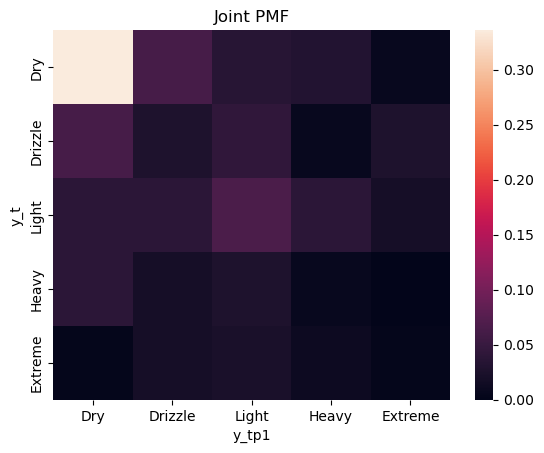

In [14]:
sns.heatmap(tab).set(title='Joint PMF')

### The Conditional PMF

- What does the conditional mass function look like?
$$\widehat{\text{pr}}[ Y_{t+1}=j | Y_t=i]
=\frac{\widehat{pr}[Y_t=i,Y_{t+1}=j]}{\widehat{\text{pr}}[Y_t=i]}.$$


In [15]:
tab = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize='index')
tab

y_tp1,Dry,Drizzle,Light,Heavy,Extreme
y_t,,,,,
Dry,0.710744,0.132231,0.074380,0.066116,0.016529
Drizzle,0.372093,0.162791,0.255814,0.046512,0.162791
Light,0.192308,0.192308,0.326923,0.192308,0.096154
Heavy,0.416667,0.208333,0.291667,0.083333,0.000000
Extreme,0.062500,0.312500,0.375000,0.187500,0.062500


[Text(0.5, 1.0, 'Conditional PMF')]

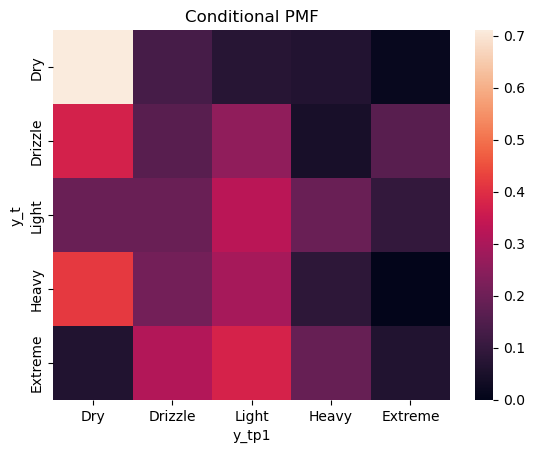

In [16]:
sns.heatmap(tab).set(title='Conditional PMF')

### Conditional Expectation

- Given the current state, how much rain do we expect to happen tomorrow?
- This is called a **conditional expectation**, and is the heart of machine learning: Given $X$, what value do we think $Y$ will take?
- Fix the current category $Y_t=i$, but use the following observation's actual precipitation amount, $X_{t+1}$, as the response, and estimate:
$$
\mathbb{E}[X_{t+1} | Y_t=i] = \dfrac{}{}
$$
- For example, the Dry-row mean answers: "Among pairs beginning with a dry observation, what was the average precipitation at the following recorded observation?" 
- We average the **actual amounts**, rather than bin labels or bin midpoints, using `.groupby` to condition on the current state.

In [17]:
df['PRCP_tp1'] = df['PRCP'].shift(-1)
df.groupby('y_t', observed=False)['PRCP_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Dry,121.0,0.096694,0.266131,0.0,0.0000,0.000,0.0400,1.61
Drizzle,43.0,0.418605,0.758022,0.0,0.0000,0.050,0.4000,3.55
Light,52.0,0.448462,0.705256,0.0,0.0375,0.180,0.6075,3.00
Heavy,24.0,0.157917,0.233368,0.0,0.0000,0.030,0.2550,0.84
Extreme,16.0,0.388750,0.519100,0.0,0.0800,0.255,0.4525,2.12


### Connecting the Three Calculations

- The **joint PMF** just gives the raw co-occurence of the current and future state, $\text{pr}[Y_{t+1}, Y_t]$
- The **marginal PMF** integrates out the current state, providing the PMF of the future state alone, $\text{pr}[Y_{t+1}]$
- The **conditional PMF** takes the ratio of the joint and marginal, providing the probability of the next state conditional on the current one, $\text{pr}[Y_{t+1}|Y_t] = \text{pr}[Y_{t+1}, Y_t]/\text{pr}[Y_t]$
- The **conditional expectation** holds the current state constant, and averages over future values,
$$
\mathbb{E}[Y_{t+1}|Y_t] =\sum_{y} y \times \text{pr}[y|Y_t]
$$

## Exercise: Daily Stock Market Changes

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**

In [18]:
df = pd.read_parquet('./data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


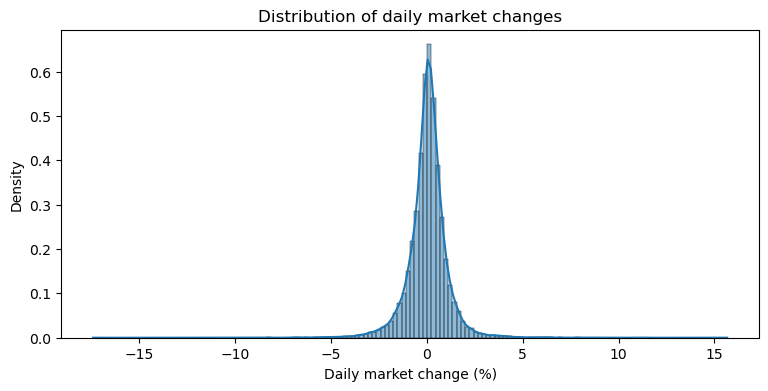

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

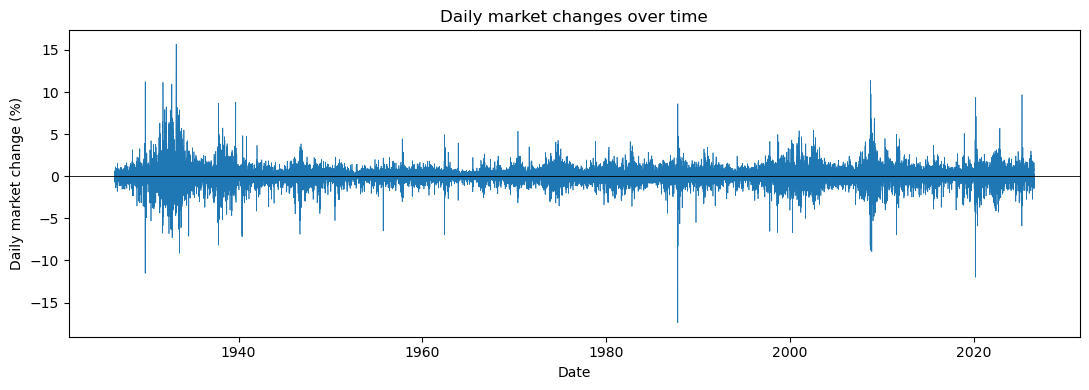

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

## Exercise

Use `market_return_pct` just as we used `PRCP` for rainfall.

1. Start with two categories: **Up** for values greater than 0, and **Down / flat** for values less than or equal to 0. Pair today's category with the next trading day's category. Compute the joint PMF, the marginals, and the conditional PMF. Are up days more common? Does the chance of an up day depend on today's category?
2. Use `pd.cut` to group `market_return_pct` into the five categories below. Compute the joint PMF, the marginals, and the conditional PMF again.

| Category | Daily market change (%) |
| --- | --- |
| Large loss | At most −1 |
| Small loss | Greater than −1, up to −0.1 |
| Near zero | Greater than −0.1, up to 0.1 |
| Small gain | Greater than 0.1, up to 1 |
| Large gain | Greater than 1 |

3. Compare the joint and conditional tables. Does the distribution of the next day's category change depending on today's category? Compare each conditional row with the next day's marginal PMF.
4. For each of today's five categories, find the **average percentage change on the next trading day**. This is the conditional expectation. Average the actual `market_return_pct` values for the next day.

### Raw Counts: Down / Flat or Up?

- Start with two categories, just as we used Dry and Wet. An exactly zero return belongs to **Down / flat**. Rows describe today's return; columns describe the next trading day's return. The final observation has no observed successor and is excluded from the paired tables.

### The Joint PMF

Divide by the total number of complete pairs to estimate $\text{pr}[Y_t=i, Y_{t+1}=j]$. The **whole table** sums to 1.

### The Marginal PMF

The `All` column gives the distribution of today's category in the paired sample; the `All` row gives the distribution of the next day's category. These describe the same set of complete pairs as the joint PMF.

### Binning a Continuous Variable

Now distinguish small changes from large ones. Apply the five categories from the exercise to `market_return_pct`.

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

Call today's category `y_t` and the next trading day's category `y_tp1`.

Now keep the sign **and** a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |


### The Joint PMF

### The Conditional PMF

Normalize each row to estimate $P(Y_{t+1}=j\mid Y_t=i)$. Each row with observations sums to 1 and describes the next day's return category, given today's category. The denominator is the number of pairs in that row, just as in the weather example.

### Conditional Expectation

As with precipitation, retain the continuous response when estimating a conditional mean. Estimate $E[r_{t+1}\mid Y_t=i]$ directly from the next day's observed log return, rather than substituting bin midpoints.

The next day's **absolute** log return measures movement size regardless of sign. Comparing it across today's categories helps reveal volatility clustering: large moves can be followed by more large moves even when their direction is uncertain. Absolute return is a simple proxy for volatility, not a conditional standard deviation.

## Points to Keep in Mind

- **Joint probabilities:** Divide by the total number of day pairs. The whole table sums to 1.
- **Conditional probabilities:** Divide by the number of pairs in the chosen row. Each row with observations sums to 1.
- **Conditional expectations:** Group by today's category and average the next day's actual percentage changes.
- **Categories are choices:** Different cutoffs can change the patterns. Categories with fewer observations give less reliable estimates.
- **The next trading day can follow a weekend or holiday.** Use the next observed row; do not add zeros for days when the market was closed.
- **Patterns describe this dataset.** They may change over time. These tables alone do not establish that today's category captures everything in the past that could help predict the next day.